# 26 — Augmentation, scaling laws and domain adaptation H1 → L1 of the CNN detector

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 60, 62 and 28 with the project's 1-D CNN (same architecture, same optimiser as notebook 07), evaluated by the mean ρ₅₀ over sine-Gaussian, pulse and chirp at FAP 10⁻² and 10⁻³ with thresholds from validation noise and bootstrap errors.

* **62. Scaling laws.** Performance against the number of training noise windows (1 000, 4 000, 16 224) for static injections and for fresh injections at every epoch.
* **60. Augmentation and label noise.** The static data set with random sign flip and circular time shift of every window at every epoch (does it cure the over-fitting that fresh injections cure?), and 5 % / 20 % of wrong labels.
* **28. Domain adaptation.** The CNN trained on H1 is applied to **L1** (thresholds from L1 noise): zero-shot, after fine-tuning on L1 chunks (fresh injections, 5 epochs) and compared with a network trained from scratch on L1.

**What it does not do.** One seed per variant: differences of a few tenths are of the order of the seed-to-seed scatter measured in notebooks 07 and 27; L1 has six chunks only (train 0, 1; validation 3, 4; test 2, 5), so the L1 numbers are noisier than the H1 ones.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, pickle, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
SNRS = sm.SNRS; MORPHS = g.MORPHS; NINJ = 300
CH, data, S1, DS = sm.load_data()
noise_tr, S1_tr = DS["train"]["noise"], S1["train"]; noise_va, S1_va = DS["val"]["noise"], S1["val"]
def make_xy(noise, sig): return np.concatenate([sm.clip(noise), sm.clip(sig)])[..., None], np.r_[np.zeros(len(noise)), np.ones(len(sig))].astype(np.float32)
Xv, yv = DS["val"]["X"], DS["val"]["yb"]
def train(noise, S1n, mode="fresh", epochs=20, seed=0, lr=2e-3, init=None, aug=False, label_noise=0.0, Xval=None, yval=None, verbose=False):
    m = sm.build_cnn(seed=seed)
    if init is not None: m.set_weights(init.get_weights())
    steps = int(np.ceil(2 * len(noise) / 128))
    m.compile(keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(0.0, epochs * steps, alpha=0.02, warmup_target=lr, warmup_steps=min(2 * steps, steps * epochs // 4)), weight_decay=1e-4), keras.losses.BinaryCrossentropy(from_logits=True))
    r = np.random.default_rng(100 + seed); sig, _, _ = sm.make_signals(noise, S1n, list(MORPHS), r); best, bw = np.inf, None
    for ep in range(epochs):
        if mode == "fresh": sig, _, _ = sm.make_signals(noise, S1n, list(MORPHS), r)
        X, y = make_xy(noise, sig)
        if aug:
            sgn = r.choice([-1.0, 1.0], len(X))[:, None, None]; sh = r.integers(-64, 65, len(X)); X = np.stack([np.roll(x, s, axis=0) for x, s in zip(X * sgn, sh)])
        if label_noise > 0: flip = r.random(len(y)) < label_noise; y = np.where(flip, 1 - y, y).astype(np.float32)
        h = m.fit(X, y, validation_data=(Xval if Xval is not None else Xv, yval if yval is not None else yv), epochs=1, batch_size=128, verbose=0, shuffle=True)
        vl = float(h.history["val_loss"][0])
        if verbose: print(f"  ep {ep + 1} val {vl:.4f}", flush=True)
        if vl < best: best, bw = vl, m.get_weights()
    m.set_weights(bw); return m, best
TEST = sm.make_test_sets(data, S1)
def score(m, x): return m.predict(sm.clip(x)[..., None], verbose=0, batch_size=1024)[:, 0]
def evaluate(m, val_noise, test_sets, B=200):
    sv = score(m, val_noise); sc = {k: score(m, x) for k, (x, _) in test_sets.items()}; out = {}
    for far in (1e-2, 1e-3):
        r = [g.bootstrap_rho(sv, [sc[(k, s)] for s in SNRS], SNRS, far, B=B, seed=3) for k in MORPHS]
        out[far] = (float(np.mean([np.nan_to_num(p[0], nan=16) for p, _ in r])), float(np.sqrt(sum(((g.ci(b[:, 0])[1] - g.ci(b[:, 0])[0]) / 2) ** 2 for _, b in r)) / 3))
    return out

## 62 and 60. Scaling with the training-set size, augmentation, label noise (H1)

In [2]:
fn = os.path.join(g.CACHE, "stats26.pkl"); RES = pickle.load(open(fn, "rb")) if os.path.exists(fn) else {}
def run(name, **kw):
    if name in RES: return
    t0_ = time.time(); n = kw.pop("n", None); idx = np.random.default_rng(5).choice(len(noise_tr), n, replace=False) if n else np.arange(len(noise_tr))
    m, best = train(noise_tr[idx], S1_tr[idx], **kw); RES[name] = dict(eval=evaluate(m, noise_va, TEST), val_loss=best, seconds=time.time() - t0_); pickle.dump(RES, open(fn, "wb")); print(name, {k: tuple(round(x, 2) for x in v) for k, v in RES[name]["eval"].items()}, "%.0f s" % RES[name]["seconds"], flush=True)
for n in (1000, 4000):
    run(f"static n={n}", n=n, mode="static", epochs=20); run(f"fresh n={n}", n=n, mode="fresh", epochs=20)
run("static n=16224", mode="static", epochs=20); run("fresh n=16224", mode="fresh", epochs=20)
run("static + augmentation (flip, shift)", mode="static", epochs=20, aug=True)
run("fresh, 5% label noise", n=4000, mode="fresh", epochs=20, label_noise=0.05); run("fresh, 20% label noise", n=4000, mode="fresh", epochs=20, label_noise=0.20)
run("static n=4000 + augmentation", n=4000, mode="static", epochs=20, aug=True)
rows = [dict(variant=k, rho50_1e2=v["eval"][1e-2][0], err_1e2=v["eval"][1e-2][1], rho50_1e3=v["eval"][1e-3][0], err_1e3=v["eval"][1e-3][1], val_loss=v["val_loss"]) for k, v in RES.items()]
SC = pd.DataFrame(rows).set_index("variant"); SC.round(3)

static n=1000 {0.01: (6.7, 0.05), 0.001: (9.61, 0.31)} 119 s


fresh n=1000 {0.01: (6.53, 0.05), 0.001: (9.33, 0.43)} 88 s


static n=4000 {0.01: (6.16, 0.04), 0.001: (7.39, 0.29)} 214 s


fresh n=4000 {0.01: (5.83, 0.04), 0.001: (7.11, 0.1)} 189 s


static n=16224 {0.01: (5.34, 0.06), 0.001: (6.48, 0.06)} 500 s


...

static + augmentation (flip, shift) {0.01: (5.32, 0.05), 0.001: (6.15, 0.08)} 492 s


fresh, 5% label noise {0.01: (5.77, 0.05), 0.001: (6.72, 0.11)} 208 s


fresh, 20% label noise {0.01: (6.21, 0.04), 0.001: (8.47, 0.5)} 195 s


static n=4000 + augmentation {0.01: (5.94, 0.05), 0.001: (7.23, 0.16)} 190 s


,rho50_1e2,err_1e2,rho50_1e3,err_1e3,val_loss
variant,,,,,
static n=1000,6.701,0.054,9.614,0.309,0.399
fresh n=1000,6.531,0.054,9.334,0.433,0.370
static n=4000,6.158,0.040,7.388,0.288,0.315
fresh n=4000,5.833,0.040,7.106,0.097,0.275
static n=16224,5.345,0.062,6.480,0.062,0.184
fresh n=16224,4.491,0.069,5.671,0.062,0.113
"static + augmentation (flip, shift)",5.321,0.048,6.150,0.079,0.238
"fresh, 5% label noise",5.767,0.049,6.724,0.108,0.295
"fresh, 20% label noise",6.207,0.044,8.474,0.498,0.407


## 28. Domain adaptation H1 → L1

In [3]:
LW = {k: g.load_coinc_chunk(k, "L1") for k in range(6)}; LS = {"train": [0, 1], "val": [3, 4], "test": [2, 5]}
def cat(sp): return np.concatenate([LW[k]["v"] for k in LS[sp]]), np.stack([np.repeat(LW[k]["S1"][None], len(LW[k]["v"]), 0) for k in LS[sp]][0] if False else np.concatenate([np.repeat(LW[k]["S1"][None], len(LW[k]["v"]), 0) for k in LS[sp]]))
Ltr, Ltr1 = cat("train"); Lva, Lva1 = cat("val"); Lte, Lte1 = cat("test")
r = np.random.default_rng(77); LTEST = {}
for kind in MORPHS:
    for snr in SNRS: i = r.choice(len(Lte), NINJ, replace=False); LTEST[(kind, snr)] = (g.inject(Lte[i], kind, float(snr), r, Lte1[i])[0], None)
sg_va, _, _ = sm.make_signals(Lva, Lva1, list(MORPHS), np.random.default_rng(78)); XvL, yvL = make_xy(Lva, sg_va)
h1 = sm.train_variant("cnn_fresh", None, None, seed=0, verbose=False)[0]
fn2 = os.path.join(g.CACHE, "stats26_L1.pkl")
if os.path.exists(fn2): LR = pickle.load(open(fn2, "rb"))
else:
    LR = {"H1-trained on H1 (reference)": evaluate(h1, noise_va, TEST), "H1-trained applied to L1 (zero-shot)": evaluate(h1, Lva, LTEST)}
    ft, _ = train(Ltr, Ltr1, mode="fresh", epochs=5, lr=3e-4, init=h1, Xval=XvL, yval=yvL); LR["fine-tuned on L1 (5 epochs)"] = evaluate(ft, Lva, LTEST)
    sc_, _ = train(Ltr, Ltr1, mode="fresh", epochs=20, Xval=XvL, yval=yvL); LR["trained from scratch on L1"] = evaluate(sc_, Lva, LTEST)
    pickle.dump(LR, open(fn2, "wb"))
DA = pd.DataFrame([dict(variant=k, rho50_1e2=v[1e-2][0], err_1e2=v[1e-2][1], rho50_1e3=v[1e-3][0], err_1e3=v[1e-3][1]) for k, v in LR.items()]).set_index("variant"); DA.round(2)

,rho50_1e2,err_1e2,rho50_1e3,err_1e3
variant,,,,
H1-trained on H1 (reference),4.57,0.08,5.66,0.07
H1-trained applied to L1 (zero-shot),5.55,0.07,6.97,0.14
fine-tuned on L1 (5 epochs),5.49,0.06,6.94,0.21
trained from scratch on L1,8.45,0.08,9.95,0.09


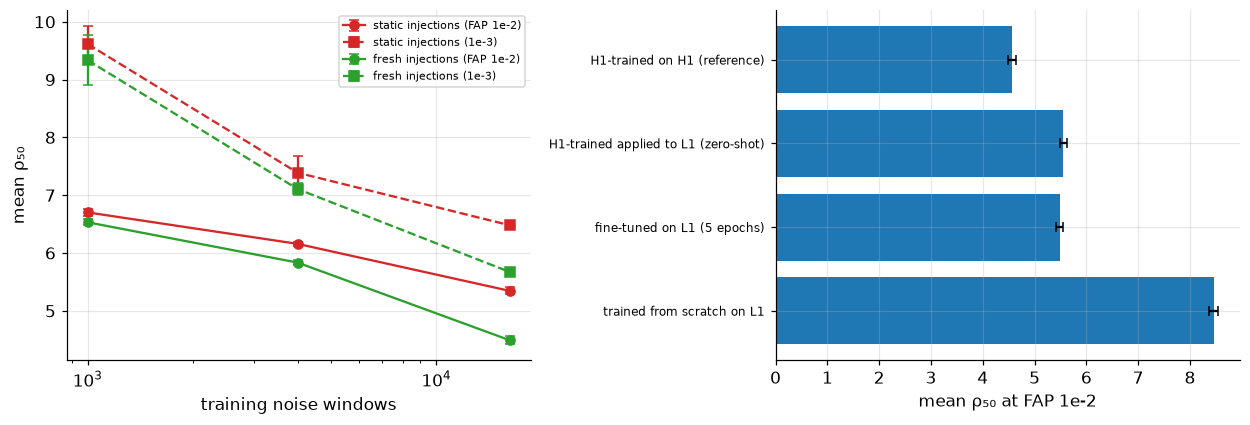

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
st, fr = SC.loc[[f"static n={n}" for n in (1000, 4000, 16224)]], SC.loc[[f"fresh n={n}" for n in (1000, 4000, 16224)]]; N = [1000, 4000, 16224]
for d, lab, c in ((st, "static injections", g.COLORS["bayes"]), (fr, "fresh injections", g.COLORS["ml"])): ax[0].errorbar(N, d.rho50_1e2, d.err_1e2, marker="o", color=c, capsize=3, label=lab + " (FAP 1e-2)"); ax[0].errorbar(N, d.rho50_1e3, d.err_1e3, marker="s", ls="--", color=c, capsize=3, label=lab + " (1e-3)")
ax[0].set_xscale("log"); ax[0].set_xlabel("training noise windows"); ax[0].set_ylabel("mean ρ₅₀"); ax[0].legend(fontsize=7)
ax[1].barh(range(len(DA)), DA.rho50_1e2, xerr=DA.err_1e2, color=g.COLORS["freq"], capsize=3); ax[1].set_yticks(range(len(DA))); ax[1].set_yticklabels(DA.index, fontsize=8); ax[1].invert_yaxis(); ax[1].set_xlabel("mean ρ₅₀ at FAP 1e-2")
fig.tight_layout(); g.savefig(fig, "fig26_scaling_adaptation"); plt.show()
g.save_json(dict(scaling=SC.reset_index().to_dict("records"), adaptation=DA.reset_index().to_dict("records")), "26_summary.json")

## Output and next step

`results/26_summary.json`, `figures/fig26_scaling_adaptation`. Next: seed study (extension 2) and the Bayesian / frequentist batch (extensions 40, 43, 57, 36, 37).